# Практикум 4. Продвинутые методы и практические кейсы

**Курс «Анализ данных и машинное обучение на финансовых рынках»**

---

### Как работать с этим блокнотом

1. Выполняйте ячейки **по порядку**: `Shift + Enter`.
2. Подойдёт Jupyter (Anaconda или python.org + pip) или Google Colab — см. инструкцию в информационном
   разделе курса. Нужны numpy, pandas, scipy, matplotlib; sklearn, statsmodels и torch — по желанию (ячейки
   с ними необязательны и пропускаются, если библиотеки нет).
3. 📘 — разбор: запустите и посмотрите результат. ✏️ — задание: допишите код вместо `...` или `# ваш код`, затем запустите
   ячейку проверки с `assert` — если ошибок нет, решение верно.
   💡 — решение под треугольником, открывайте после честной попытки.
4. Перед сдачей: **Kernel → Restart & Run All**.

### Что будет к концу блокнота

Вы напишете нейросеть на numpy и проверите её градиенты, сравните её с простыми моделями,
смешаете модели, классифицируете новости наивным Байесом и измерите реакцию рынка, обработаете тики потоково,
примените байесовское обновление и проверите, что дают переборы торговых правил. Каждое задание проверяется ячейкой
с `assert`.

In [1]:
import json, os, sys, time, random
from datetime import datetime, timedelta, timezone
from pprint import pprint
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
%matplotlib inline
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 140)
BLUE, ORANGE = "#34519E", "#CF7A2A"      # цвета серий на графиках
NAVY, GREY = "#1E2761", "#9AA3B5"
IN_COLAB = "google.colab" in sys.modules
print("Python", sys.version.split()[0], "| pandas", pd.__version__, "| Colab" if IN_COLAB else "| локально")

Python 3.14.5 | pandas 3.1.1 | локально


Данные — условная фондовая площадка **«Меридиан»** (все компании вымышлены), затем — ячейка **«Инструменты курса»** (функции тем 1–3).

In [2]:
# Сквозной кейс курса «Анализ данных и машинное обучение на финансовых рынках» — «Меридиан»: условная
# фондовая площадка. Все компании, тикеры, котировки и новости вымышлены, совпадения с реальными компаниями
# случайны; генерация детерминирована (seed 2026), у всех получаются одинаковые числа. Только стандартная библиотека.
#   STOCKS      — 12 акций четырёх секторов: тикер, название, сектор, число акций (млн), лот
#   DATES       — торговые дни 09.01.2019–30.09.2026 (без выходных и праздников)
#   PRICES      — дневные данные акций: date, ticker, open, high, low, close (без корректировок), adj_close
#                 (с учётом дивидендов и сплитов), volume (шт.)
#   INDEX       — индекс широкого рынка MRDX: date, open, high, low, close
#   FX          — условный курс доллара: date, usd
#   NEWS        — новости компаний (кроме KLSU и TVRA): date, ticker, headline, label (разметка аналитика: позитив/негатив/нейтрально)
#   DIVIDENDS, SPLITS — корпоративные действия (дата отсечки, размер дивиденда на акцию; коэффициент сплита)
#   RAW_PRICES  — «сырая» выгрузка котировок трёх акций с типичными дефектами (ключ — RAW_DEFECTS)
#   ticks(ticker, start, end) — ЛЕНИВЫЙ генератор сделок внутри дня (время, цена, количество, сторона)
import math as _m
import random as _random
from datetime import date as _date, timedelta as _td

_SEED = 2026
_TITLE = "Меридиан"
_INDEX = "MRDX"
_R = _random.Random(_SEED)
_D0, _D1 = _date(2019, 1, 9), _date(2026, 9, 30)

_STOCKS = [  # тикер, название, сектор, бета рынка, бета курса, σ собств., лаг рынка, цена, акций (млн), див. доходн.
    ("BRZB", "Бриз-Банк", "финансы", 1.20, -0.10, 0.012, 0.00, 250, 2400, 0.08),
    ("AQLF", "Аквилон Финанс", "финансы", 1.05, -0.05, 0.014, 0.00, 85, 3100, 0.06),
    ("PKRV", "Покров Страхование", "финансы", 0.85, 0.00, 0.011, 0.00, 410, 420, 0.07),
    ("GRZN", "Горизонт-Нефть", "энергетика", 0.95, 0.55, 0.011, 0.00, 640, 1500, 0.10),
    ("SRMG", "Сарматгаз", "энергетика", 0.85, 0.45, 0.013, 0.00, 175, 5200, 0.09),
    ("VLTE", "Вольта Энерго", "энергетика", 0.70, 0.20, 0.010, 0.00, 32, 22000, 0.07),
    ("KLSU", "Колос-Юг", "агро", 0.60, 0.15, 0.015, 0.35, 120, 900, 0.04),
    ("TVRA", "Таврида-Агро", "агро", 0.60, 0.15, 0.015, 0.35, 118, 760, 0.00),
    ("NVGR", "Ниваград", "агро", 0.55, 0.10, 0.016, 0.35, 56, 1300, 0.03),
    ("PXLS", "Пиксель Софт", "технологии", 1.35, -0.30, 0.017, 0.00, 2400, 120, 0.00),
    ("NSFT", "Ноосфера Телеком", "технологии", 1.10, -0.20, 0.013, 0.00, 310, 1700, 0.02),
    ("KBRM", "Кибериум", "технологии", 1.45, -0.35, 0.020, 0.00, 95, 2600, 0.00)]
_LAG_UNTIL = _date(2024, 6, 30)       # после этой даты запаздывание агроакций почти исчезает (дрейф)
_LAG_AFTER = 0.0
_SPLIT = ("PXLS", _date(2023, 3, 15), 10)
_STRESS = {_date(2020, 3, 9): -4.0, _date(2020, 3, 12): -3.0, _date(2020, 3, 16): -3.5}
_HOLI = {(1, k) for k in range(1, 9)} | {(2, 23), (3, 8), (5, 1), (5, 9), (6, 12), (11, 4)}

STOCKS = [{"ticker": s[0], "name": s[1], "sector": s[2], "shares_mln": s[8], "lot": 10 if s[7] < 1000 else 1}
          for s in _STOCKS]


def _t(r, nu):
    """Стандартизованное t-распределение (дисперсия 1): «толстые хвосты»."""
    z = r.gauss(0, 1)
    chi = 2 * r.gammavariate(nu / 2, 1)
    return z / _m.sqrt(chi / nu) / _m.sqrt(nu / (nu - 2))


DATES = []
_d = _D0
while _d <= _D1:
    if _d.weekday() < 5 and (_d.month, _d.day) not in _HOLI:
        DATES.append(_d)
    _d += _td(days=1)
_T = len(DATES)

# ---------- рынок: GJR-GARCH(1,1) с t-шумом, условный кризис весны 2020 ----------
_MU, _OM, _AL, _GA, _BE = 0.00035, 3.0e-6, 0.04, 0.06, 0.90
_rm, _sig = [], []
_s2, _eps = 0.0001, 0.0
for _d in DATES:
    _s2 = _OM + (_AL + _GA * (_eps < 0)) * _eps ** 2 + _BE * _s2 if _rm else _s2
    _z = _t(_R, 6)
    _z = _STRESS.get(_d, _z * (1.15 if _z < 0 else 0.85) + 0.115)  # падения резче роста: отрицательная асимметрия
    _eps = _m.sqrt(_s2) * _z
    _rm.append(_MU + _eps)
    _sig.append(_m.sqrt(_s2))
# ---------- курс и секторы ----------
_fx = [0.00015 - 0.30 * (_rm[i] - _MU) + max(0.003, 0.004 + 0.25 * (_sig[i] - 0.01)) * _t(_R, 5) for i in range(_T)]
_SECT = sorted({s[2] for s in _STOCKS})
_fs = {k: [0.009 * _m.sqrt(_sig[i] / 0.01) * _t(_R, 5) for i in range(_T)] for k in _SECT}

# ---------- новости: шаблоны заголовков ----------
_POS = ["«{n}» увеличивает чистую прибыль на {p} %", "«{n}» повышает прогноз выручки на год",
        "«{n}» объявляет о выкупе акций на {b} млрд руб.", "Рейтинговое агентство повышает рейтинг «{n}»",
        "«{n}» получает крупный контракт на {b} млрд руб.", "Выручка «{n}» растёт на {p} % — выше ожиданий",
        "Совет директоров «{n}» рекомендует рекордные дивиденды", "«{n}» выходит на новый рынок и расширяет производство",
        "Аналитики улучшают оценку «{n}» после сильного отчёта", "«{n}» сокращает долг и снижает расходы"]
_NEG = ["Чистая прибыль «{n}» снижается на {p} %", "«{n}» понижает прогноз выручки на год",
        "«{n}» отменяет выплату дивидендов", "Рейтинговое агентство понижает рейтинг «{n}»",
        "«{n}» теряет крупный контракт", "Выручка «{n}» падает на {p} % — хуже ожиданий",
        "Против «{n}» подан иск на {b} млрд руб.", "«{n}» сообщает об убытке и росте долга",
        "Аналитики ухудшают оценку «{n}» после слабого отчёта", "«{n}» приостанавливает производство из-за аварии"]
_NEU = ["«{n}» проведёт годовое собрание акционеров", "«{n}» опубликует отчётность на следующей неделе",
        "«{n}» назначает нового финансового директора", "«{n}» представит стратегию на дне инвестора",
        "«{n}» меняет аудитора", "«{n}» разместит облигации на {b} млрд руб."]
_MIX = [("Несмотря на снижение выручки, «{n}» увеличивает прибыль на {p} %", 1),
        ("Прибыль «{n}» растёт, но компания понижает прогноз на год", -1),
        ("«{n}» снижает расходы, однако теряет крупный контракт", -1),
        ("Убыток «{n}» сокращается, компания возвращается к росту выручки", 1)]
_LAB = {1: "позитив", -1: "негатив", 0: "нейтрально"}

# ---------- акции ----------
_RS = _random.Random(_SEED + 1)
_rets, _news_eff, NEWS = {}, {}, []
_spread = 0.0
for _s in _STOCKS:
    _tk, _nm, _sec, _b, _g, _sd, _lag = _s[:7]
    _a = 0.00012 if _sec == "энергетика" else (0.0 if _sec == "технологии" else 0.00006)
    _r, _carry, _eff, _h, _e = [], 0.0, {}, 1.0, 0.0
    for _i, _d in enumerate(DATES):
        _lg = (_lag if _d <= _LAG_UNTIL else _LAG_AFTER) if _lag else 0.0
        _h = 0.02 + 0.12 * _e ** 2 + 0.86 * _h                    # собственный GARCH(1,1) шума акции
        _scale = (0.7 + 0.3 * _sig[_i] / 0.01) * _m.sqrt(_h)
        _e = _t(_RS, 5)
        _x = (_a + _b * (_rm[_i] - _MU) + _lg * (_rm[_i - 1] - _MU if _i else 0.0) + _g * _fx[_i] + _fs[_sec][_i]
              + _sd * _scale * _e + _carry)
        _carry = 0.0
        if _tk not in ("KLSU", "TVRA") and _RS.random() < 0.045:                  # новость о компании
            _u = _RS.random()
            _sent = 1 if _u < 0.40 else (-1 if _u < 0.75 else 0)
            _mix = _sent != 0 and _RS.random() < 0.12
            if _mix:
                _tpl, _sent = _RS.choice([x for x in _MIX])
            else:
                _tpl = _RS.choice({1: _POS, -1: _NEG, 0: _NEU}[_sent])
            _jump = _sent * (0.02 + 0.015 * abs(_RS.gauss(0, 1)))
            if _sent and _RS.random() < 0.12:
                _jump *= -0.6                                          # рынок «не согласился» с новостью
            if not _sent:
                _jump = 0.004 * _RS.gauss(0, 1)
            _x += _jump
            _carry = 0.25 * _jump                                      # дрейф после новости на следующий день
            _lab = _sent if _RS.random() > 0.08 else _RS.choice([v for v in (1, -1, 0) if v != _sent])
            _head = _tpl.format(n=_nm, p=_RS.randint(5, 45), b=_RS.randint(2, 60))
            _head = _head[0].upper() + _head[1:]
            NEWS.append({"date": _d.isoformat(), "ticker": _tk, "headline": _head, "label": _LAB[_lab]})
            _eff[_i] = _jump
        _r.append(_x)
    if _tk == "TVRA":                     # коинтеграция с KLSU: спред возвращается к среднему
        _r, _sp, _RC = [], [], _random.Random(_SEED + 5)
        for _i in range(_T):
            _new = 0.96 * _spread + 0.013 * _RC.gauss(0, 1)
            _r.append(_rets["KLSU"][_i] + (_new - _spread))
            _spread = _new
    _rets[_tk], _news_eff[_tk] = _r, _eff

# ---------- инсайдерский след: аномальный объём накануне части позитивных новостей ----------
_RI = _random.Random(_SEED + 9)
_pos_news = [(k, n) for k, n in enumerate(NEWS) if n["label"] == "позитив"]
_INSIDE = {(n["ticker"], n["date"]) for k, n in _RI.sample(_pos_news, 8)}
_POS_IDX = {d.isoformat(): i for i, d in enumerate(DATES)}

# ---------- цены, объёмы, дивиденды, сплит ----------
_RP = _random.Random(_SEED + 2)
PRICES, DIVIDENDS, SPLITS, _BY = [], [], [], {}
for _k, _s in enumerate(_STOCKS):
    _tk, _sd, _p0, _shares, _dy = _s[0], _s[5], _s[7], _s[8], _s[9]
    _p, _rows, _ev = float(_p0), [], []
    _base = 4.0e6 / (_p0 / 100) ** 0.6
    _ins = {_POS_IDX[d] - 1 for t, d in _INSIDE if t == _tk}
    _newsd = set(_news_eff[_tk])
    for _i, _d in enumerate(DATES):
        _r = _rets[_tk][_i]
        _prev = _p
        _div = 0.0
        if _dy and _d.month == 7 and 8 + _k <= _d.day and not any(e[0] == "div" and e[1].year == _d.year for e in _ev):
            _div = round(_dy * _prev * (0.8 + 0.4 * _RP.random()), 2)
            _ev.append(("div", _d, _div))
            DIVIDENDS.append({"ticker": _tk, "ex_date": _d.isoformat(), "dividend": _div})
        _p = _prev * _m.exp(_r) - _div
        if _tk == _SPLIT[0] and _d == _SPLIT[1]:
            _p /= _SPLIT[2]
            _ev.append(("split", _d, _SPLIT[2]))
            SPLITS.append({"ticker": _tk, "date": _d.isoformat(), "ratio": _SPLIT[2]})
        _gap = 0.3 * _r + 0.002 * _RP.gauss(0, 1)
        _o = (_prev - _div) * _m.exp(_gap) / (_SPLIT[2] if (_tk == _SPLIT[0] and _d == _SPLIT[1]) else 1)
        _intra = _sd * (0.6 + 0.4 * _sig[_i] / 0.01) + 0.5 * _sig[_i]
        _hi = max(_o, _p) * _m.exp(abs(_RP.gauss(0, 1)) * _intra * 0.6)
        _lo = min(_o, _p) * _m.exp(-abs(_RP.gauss(0, 1)) * _intra * 0.6)
        _tot = _m.sqrt((_sig[_i]) ** 2 + (_sd * (0.6 + 0.4 * _sig[_i] / 0.01)) ** 2)
        _vol = (_base * (1 + 0.08 * (_d.year - 2019)) * (_sig[_i] / 0.01) ** 0.5
                * _m.exp(0.35 * _RP.gauss(0, 1) + 0.45 * min(abs(_r) / _tot, 5)))
        if _i in _newsd:
            _vol *= 2.5
        if _i in _ins:
            _vol *= 6.0
        if _tk == _SPLIT[0] and _d >= _SPLIT[1]:
            _vol *= _SPLIT[2]
        _nd = 2 if _p < 1000 else 1
        _rows.append([_d.isoformat(), _tk, round(_o, _nd), round(_hi, _nd), round(_lo, _nd), round(_p, _nd),
                      None, int(round(_vol, -1))])
    # скорректированная цена: назад от последней даты, множители дивидендов и сплитов
    _f, _evd = 1.0, {e[1].isoformat(): e for e in _ev}
    for _j in range(len(_rows) - 1, -1, -1):
        _rows[_j][6] = round(_rows[_j][5] * _f, 4)
        e = _evd.get(_rows[_j][0])
        if e is not None and _j:
            _f *= (1 - e[2] / _rows[_j - 1][5]) if e[0] == "div" else 1 / e[2]
    _keys = ("date", "ticker", "open", "high", "low", "close", "adj_close", "volume")
    _BY[_tk] = [dict(zip(_keys, r)) for r in _rows]
for _i in range(_T):
    for _s in _STOCKS:
        PRICES.append(_BY[_s[0]][_i])

# ---------- индекс и курс ----------
_RX = _random.Random(_SEED + 3)
INDEX, FX = [], []
_lv, _usd = 1000.0, 70.0
for _i, _d in enumerate(DATES):
    _o = _lv * _m.exp(0.3 * _rm[_i] + 0.001 * _RX.gauss(0, 1))
    _lv *= _m.exp(_rm[_i])
    _w = 0.6 * _sig[_i]
    INDEX.append({"date": _d.isoformat(), "open": round(_o, 2),
                  "high": round(max(_o, _lv) * _m.exp(abs(_RX.gauss(0, 1)) * _w), 2),
                  "low": round(min(_o, _lv) * _m.exp(-abs(_RX.gauss(0, 1)) * _w), 2), "close": round(_lv, 2)})
    _usd *= _m.exp(_fx[_i])
    FX.append({"date": _d.isoformat(), "usd": round(_usd, 4)})

# ---------- «сырая» выгрузка с дефектами (3 акции) ----------
_RR = _random.Random(_SEED + 7)
RAW_PRICES, RAW_DEFECTS = [], {"пропущенный день": 0, "полный дубль строки": 0, "дата дд.мм.гггг": 0,
                               "цена строкой с запятой": 0, "цена ×100 (ошибка запятой)": 0,
                               "нулевой объём": 0, "зависшая цена (повтор вчерашней)": 0, "пропуск цены": 0}
for _tk in ("BRZB", "KLSU", "PXLS"):
    _prev = None
    for _row in _BY[_tk]:
        _x = {k: _row[k] for k in ("date", "ticker", "open", "high", "low", "close", "volume")}
        _u = _RR.random()
        if _u < 0.012:
            RAW_DEFECTS["пропущенный день"] += 1
            continue
        elif _u < 0.032:
            _x["date"] = _date.fromisoformat(_x["date"]).strftime("%d.%m.%Y"); RAW_DEFECTS["дата дд.мм.гггг"] += 1
        elif _u < 0.047:
            _x["close"] = f"{_x['close']:.2f}".replace(".", ","); RAW_DEFECTS["цена строкой с запятой"] += 1
        elif _u < 0.050:
            _x["close"] = round(_x["close"] * 100, 2); RAW_DEFECTS["цена ×100 (ошибка запятой)"] += 1
        elif _u < 0.056:
            _x["volume"] = 0; RAW_DEFECTS["нулевой объём"] += 1
        elif _u < 0.061 and _prev is not None and isinstance(_prev["close"], float):
            _x["close"] = _prev["close"]
            RAW_DEFECTS["зависшая цена (повтор вчерашней)"] += 1
        elif _u < 0.068:
            _x["close"] = None; RAW_DEFECTS["пропуск цены"] += 1
        RAW_PRICES.append(_x)
        if _RR.random() < 0.01:
            RAW_PRICES.append(dict(_x)); RAW_DEFECTS["полный дубль строки"] += 1
        _prev = _x


def ticks(ticker: str, start: str, end: str, seed: int = _SEED):
    """ЛЕНИВЫЙ генератор сделок за торговые дни [start, end]: кортежи (время «ГГГГ-ММ-ДД ЧЧ:ММ:СС», тикер, цена,
    количество, сторона «B»/«S»). Цены открытия и закрытия дня совпадают с PRICES; около 2–6 тыс. сделок в день."""
    for row in _BY[ticker]:
        if not (start <= row["date"] <= end):
            continue
        r = _random.Random(f"{seed}-{ticker}-{row['date']}")
        n = max(300, min(8000, row["volume"] // 900))
        u = sorted(r.betavariate(0.65, 0.65) for _ in range(n))          # U-образная активность в течение сессии
        lo, lc = _m.log(row["open"]), _m.log(row["close"])
        sig = max(_m.log(row["high"] / row["low"]) / 1.6, 0.002)          # волатильность дня — по диапазону H/L
        w, tp, path = 0.0, 0.0, []
        for x in u:
            w += r.gauss(0, 1) * _m.sqrt(max(x - tp, 1e-9)) * sig
            tp = x
            path.append(w)
        wl = path[-1]
        half = max(0.01, row["close"] * 0.0004)
        for x, wx in zip(u, path):
            side = "B" if r.random() < 0.5 else "S"
            mid = _m.exp(lo + wx - x * wl + x * (lc - lo))
            sec = 36000 + int(x * 31200)                                   # 10:00–18:40
            yield (f"{row['date']} {sec // 3600:02d}:{sec // 60 % 60:02d}:{sec % 60:02d}", ticker,
                   round(mid + (half if side == "B" else -half), 2), int(r.paretovariate(1.6) * 10), side)

print(f"{_TITLE}: акций {len(STOCKS)}, торговых дней {len(DATES)} ({DATES[0]} – {DATES[-1]}), строк котировок {len(PRICES)}, новостей {len(NEWS)}")

Меридиан: акций 12, торговых дней 1943 (2019-01-09 – 2026-09-30), строк котировок 23316, новостей 884


In [3]:
# Инструменты курса «АД и МО на финансовых рынках»: функции, написанные в темах 1–3 (numpy, pandas, scipy).
# В практикумах тем 3–4 эта ячейка идёт сразу после данных кейса.
import numpy as np
import pandas as pd
from scipy import stats


def panel(field="adj_close"):
    """Таблица «дата × тикер» по полю PRICES (по умолчанию — скорректированная цена)."""
    p = pd.DataFrame(PRICES).pivot(index="date", columns="ticker", values=field)
    p.index = pd.to_datetime(p.index)
    return p[[s["ticker"] for s in STOCKS]]


def index_close():
    s = pd.DataFrame(INDEX).set_index("date").close
    s.index = pd.to_datetime(s.index)
    return s


def ols(X, y):
    """МНК со свободным членом: коэффициенты, стандартные ошибки, t-статистики, R²."""
    X = np.column_stack([np.ones(len(y)), np.asarray(X, float)])
    y = np.asarray(y, float)
    b, *_ = np.linalg.lstsq(X, y, rcond=None)
    e = y - X @ b
    s2 = e @ e / (len(y) - X.shape[1])
    se = np.sqrt(np.diag(s2 * np.linalg.inv(X.T @ X)))
    return {"coef": b, "se": se, "t": b / se, "r2": 1 - e @ e / ((y - y.mean()) @ (y - y.mean()))}


def fit_logit(X, y, l2=0.0, iters=50):
    """Логистическая регрессия методом Ньютона (IRLS); l2 — штраф на коэффициенты (не на свободный член)."""
    X = np.column_stack([np.ones(len(y)), np.asarray(X, float)])
    y = np.asarray(y, float)
    w = np.zeros(X.shape[1])
    pen = l2 * np.eye(X.shape[1]); pen[0, 0] = 0
    for _ in range(iters):
        p = 1 / (1 + np.exp(-X @ w))
        g = X.T @ (p - y) + pen @ w
        H = X.T @ (X * (p * (1 - p))[:, None]) + pen
        step = np.linalg.solve(H, g)
        w -= step
        if np.abs(step).max() < 1e-8:
            break
    return w


def predict_logit(w, X):
    return 1 / (1 + np.exp(-(w[0] + np.asarray(X, float) @ w[1:])))


def auc(y, score):
    """Площадь под ROC-кривой = вероятность, что случайный «1» получит оценку выше случайного «0»."""
    y = np.asarray(y).astype(bool)
    r = stats.rankdata(score)
    n1, n0 = y.sum(), (~y).sum()
    return (r[y].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)


def roc_points(y, score):
    """Точки ROC-кривой (FPR, TPR) по всем порогам."""
    y = np.asarray(y).astype(bool)
    o = np.argsort(-np.asarray(score), kind="stable")
    tp, fp = np.cumsum(y[o]), np.cumsum(~y[o])
    return np.r_[0, fp / (~y).sum()], np.r_[0, tp / y.sum()]


def gini(y):
    p = np.mean(y) if len(y) else 0.0
    return 2 * p * (1 - p)


def best_split(x, y, min_leaf=20):
    """Лучший порог по одному признаку: минимум взвешенного индекса Джини (векторно, по отсортированным данным)."""
    o = np.argsort(x, kind="stable"); xs, ys = x[o], y[o]
    n = len(y); k = np.arange(1, n)
    c = np.cumsum(ys)[:-1]
    pl, pr = c / k, (ys.sum() - c) / (n - k)
    g = (k * 2 * pl * (1 - pl) + (n - k) * 2 * pr * (1 - pr)) / n
    ok = (k >= min_leaf) & (n - k >= min_leaf) & (xs[1:] > xs[:-1])
    if not ok.any():
        return None, np.inf
    j = np.argmin(np.where(ok, g, np.inf))
    return (xs[j] + xs[j + 1]) / 2, g[j]


def fit_tree(X, y, depth=3, min_leaf=20, features=None, rng=None):
    """Дерево классификации CART. Узел — словарь: лист {"p": доля 1} или {"f", "thr", "left", "right"}."""
    X, y = np.asarray(X, float), np.asarray(y, float)
    node = {"p": y.mean() if len(y) else 0.5, "n": len(y)}
    if depth == 0 or len(y) < 2 * min_leaf or y.min() == y.max():
        return node
    cols = range(X.shape[1]) if features is None else rng.choice(X.shape[1], features, replace=False)
    best = (None, None, gini(y))
    for f in cols:
        thr, g = best_split(X[:, f], y, min_leaf)
        if thr is not None and g < best[2] - 1e-12:
            best = (f, thr, g)
    if best[0] is None:
        return node
    f, thr = best[0], best[1]
    m = X[:, f] <= thr
    node.update(f=int(f), thr=float(thr),
                left=fit_tree(X[m], y[m], depth - 1, min_leaf, features, rng),
                right=fit_tree(X[~m], y[~m], depth - 1, min_leaf, features, rng))
    return node


def predict_tree(node, X):
    X = np.asarray(X, float)
    out = np.empty(len(X))
    for i, x in enumerate(X):
        nd = node
        while "f" in nd:
            nd = nd["left"] if x[nd["f"]] <= nd["thr"] else nd["right"]
        out[i] = nd["p"]
    return out


def fit_forest(X, y, n_trees=100, depth=4, min_leaf=30, features=None, seed=0):
    """Случайный лес: деревья на бутстреп-выборках со случайным подмножеством признаков в каждом узле."""
    X, y = np.asarray(X, float), np.asarray(y, float)
    rng = np.random.default_rng(seed)
    k = features or max(1, int(np.sqrt(X.shape[1])))
    trees = []
    for _ in range(n_trees):
        i = rng.integers(0, len(y), len(y))
        trees.append(fit_tree(X[i], y[i], depth, min_leaf, k, rng))
    return trees


def predict_forest(trees, X):
    return np.mean([predict_tree(t, X) for t in trees], axis=0)


def make_features(ticker):
    """Признаки на закрытие дня t и цель — рост акции в день t+1 (y = 1). Только прошлое и настоящее дня t."""
    px, vol = panel()[ticker], panel("volume")[ticker]
    idx, usd = index_close(), pd.DataFrame(FX).set_index("date").usd
    usd.index = pd.to_datetime(usd.index)
    r, ri = np.log(px).diff(), np.log(idx).diff()
    up, dn = r.clip(lower=0).rolling(14).mean(), (-r).clip(lower=0).rolling(14).mean()
    news = pd.DataFrame(NEWS)
    news = news[news.ticker == ticker].assign(s=lambda d: d.label.map({"позитив": 1, "негатив": -1, "нейтрально": 0}))
    sent = news.groupby(pd.to_datetime(news.date)).s.sum().reindex(px.index, fill_value=0)
    f = pd.DataFrame({
        "idx_r0": ri, "idx_r5": ri.rolling(5).sum(), "own_r0": r, "own_r5": r.rolling(5).sum(),
        "own_r20": r.rolling(20).sum(), "vol20": r.rolling(20).std(), "idx_vol20": ri.rolling(20).std(),
        "vol_z": (np.log(vol) - np.log(vol).rolling(20).mean()) / np.log(vol).rolling(20).std(),
        "ma_gap": px / px.rolling(20).mean() - 1, "rsi14": 100 * up / (up + dn),
        "fx_r0": np.log(usd).diff(), "news0": sent})
    f["r_next"] = r.shift(-1)
    f["y"] = (f.r_next > 0).astype(int)
    return f.dropna()


FEATURES = ["idx_r0", "idx_r5", "own_r0", "own_r5", "own_r20", "vol20", "idx_vol20", "vol_z", "ma_gap", "rsi14",
            "fx_r0", "news0"]


def standardize(train, test):
    """Масштабирование по среднему и ст. отклонению ОБУЧАЮЩЕЙ части (никаких сведений из теста)."""
    m, s = train.mean(), train.std().replace(0, 1)
    return (train - m) / s, (test - m) / s


def walk_forward(df, fit, predict, cols, start="2022-01-01", step=63, min_train=500):
    """Расширяющееся окно: обучение на всём до блока, прогноз на следующие step дней, сдвиг на step."""
    idx = df.index
    pos = int(np.searchsorted(idx, pd.Timestamp(start)))
    out = []
    while pos < len(df):
        tr, te = df.iloc[:pos], df.iloc[pos:pos + step]
        if len(tr) >= min_train:
            a, b = standardize(tr[cols], te[cols])
            model = fit(a.to_numpy(), tr.y.to_numpy())
            out.append(pd.Series(predict(model, b.to_numpy()), index=te.index))
        pos += step
    return pd.concat(out)


def sharpe(r, periods=252):
    r = pd.Series(r).dropna()
    return float(r.mean() / r.std() * np.sqrt(periods)) if r.std() > 0 else 0.0


def max_drawdown(r):
    """Максимальная просадка по ряду лог-доходностей (доля от пика, отрицательное число)."""
    w = np.exp(pd.Series(r).fillna(0).cumsum())
    return float((w / w.cummax() - 1).min())

print("Инструменты курса загружены:", ", ".join(sorted(k for k in dir() if k in {"panel", "index_close", "ols", "fit_logit", "predict_logit", "auc", "roc_points", "fit_tree", "predict_tree", "fit_forest", "predict_forest", "make_features", "walk_forward", "sharpe", "max_drawdown"})))

Инструменты курса загружены: auc, fit_forest, fit_logit, fit_tree, index_close, make_features, max_drawdown, ols, panel, predict_forest, predict_logit, predict_tree, roc_points, sharpe, walk_forward


## 1. Нейросеть на numpy 📘

Прямой проход, обратное распространение, Adam; на нелинейной задаче сеть побеждает логистическую регрессию.

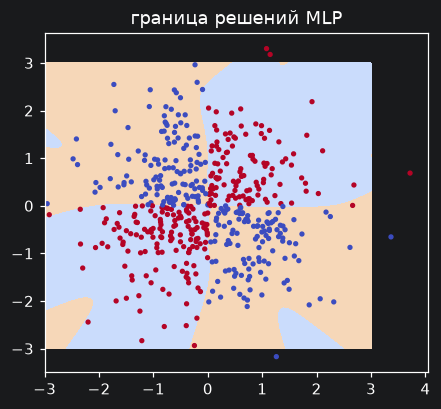

точность MLP на новых точках: 0.984


In [4]:
# Многослойный перцептрон на numpy: прямой проход, обратное распространение, Adam, ранняя остановка
def mlp_predict(params, X):
    W1, b1, W2, b2 = params
    return 1 / (1 + np.exp(-(np.tanh(X @ W1 + b1) @ W2 + b2)))

def mlp_loss(params, X, y, l2=0.0):
    p = np.clip(mlp_predict(params, X), 1e-12, 1 - 1e-12)
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p)) + 0.5 * l2 * (np.sum(params[0] ** 2) + np.sum(params[2] ** 2))

def mlp_fit(X, y, hidden=8, lr=0.01, epochs=400, l2=1e-2, seed=0, Xv=None, yv=None, patience=40):
    rng = np.random.default_rng(seed)
    params = [rng.normal(0, 1 / np.sqrt(X.shape[1]), (X.shape[1], hidden)), np.zeros(hidden),
              rng.normal(0, 1 / np.sqrt(hidden), hidden), np.zeros(1)]
    m = [np.zeros_like(q) for q in params]; v = [np.zeros_like(q) for q in params]
    best, best_params, wait = -np.inf, params, 0
    for ep in range(1, epochs + 1):
        W1, b1, W2, b2 = params
        H = np.tanh(X @ W1 + b1)
        g = (1 / (1 + np.exp(-(H @ W2 + b2))) - y) / len(y)
        dH = np.outer(g, W2) * (1 - H ** 2)
        grads = [X.T @ dH + l2 * W1, dH.sum(0), H.T @ g + l2 * W2, np.array([g.sum()])]
        for i, gr in enumerate(grads):
            m[i] = 0.9 * m[i] + 0.1 * gr; v[i] = 0.999 * v[i] + 0.001 * gr ** 2
            params[i] = params[i] - lr * (m[i] / (1 - 0.9 ** ep)) / (np.sqrt(v[i] / (1 - 0.999 ** ep)) + 1e-8)
        if Xv is not None:
            score = auc(yv, mlp_predict(params, Xv))
            if score > best:
                best, best_params, wait = score, [q.copy() for q in params], 0
            else:
                wait += 1
                if wait > patience:
                    break
    return best_params if Xv is not None else params

# нелинейная задача «шахматная доска»: граница решений сети
rng = np.random.default_rng(1)
Xt = rng.normal(size=(2000, 2)); yt = (Xt[:, 0] * Xt[:, 1] > 0).astype(float)
net = mlp_fit(Xt[:1500], yt[:1500], hidden=8, lr=0.05, epochs=500, l2=0.0)
gx, gy = np.meshgrid(np.linspace(-3, 3, 120), np.linspace(-3, 3, 120))
zz = mlp_predict(net, np.column_stack([gx.ravel(), gy.ravel()])).reshape(gx.shape)
plt.figure(figsize=(4.5, 4)); plt.contourf(gx, gy, zz, levels=[0, 0.5, 1], colors=["#F6D7B8", "#CADCFC"])
plt.scatter(Xt[1500:, 0], Xt[1500:, 1], c=yt[1500:], s=6, cmap="coolwarm"); plt.title("граница решений MLP"); plt.show()
print("точность MLP на новых точках:", ((mlp_predict(net, Xt[1500:]) > 0.5) == yt[1500:]).mean())

## 2. Нейросеть на рынке 📘

На слабом линейном сигнале сеть не лучше логистической регрессии.

In [5]:
# MLP на рынке: NVGR, обучение 2019–2021, ранняя остановка по 2022, тест 2023 — 06.2024
f = make_features("NVGR")
tr, va, te = f.loc[:"2021"], f.loc["2022"], f.loc["2023":"2024-06"]
cs = FEATURES
m, s = tr[cs].mean(), tr[cs].std()
A, V, B = [((x[cs] - m) / s).to_numpy() for x in (tr, va, te)]
net = mlp_fit(A, tr.y.to_numpy(), Xv=V, yv=va.y.to_numpy())
p_mlp = mlp_predict(net, B)
p_log = predict_logit(fit_logit(A, tr.y, l2=1.0), B)
p_rf = predict_forest(fit_forest(A, tr.y.to_numpy(), 150, 4, 30, seed=1), B)
{k: round(auc(te.y, v_), 3) for k, v_ in {"логит": p_log, "лес": p_rf, "MLP": p_mlp}.items()}

{'логит': np.float64(0.615),
 'лес': np.float64(0.554),
 'MLP': np.float64(0.611)}

## 3. PyTorch (необязательно) 📘

Если torch не установлен, ячейка просто сообщит об этом.

In [6]:
# Необязательно: та же сеть в PyTorch (если библиотека установлена; в Colab она есть)
try:
    import torch
    torch.manual_seed(0)
    model = torch.nn.Sequential(torch.nn.Linear(A.shape[1], 8), torch.nn.Tanh(), torch.nn.Linear(8, 1))
    opt = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=1e-2)
    Xa, ya = torch.tensor(A, dtype=torch.float32), torch.tensor(tr.y.to_numpy(), dtype=torch.float32)
    for _ in range(200):
        opt.zero_grad()
        loss = torch.nn.functional.binary_cross_entropy_with_logits(model(Xa).squeeze(1), ya)
        loss.backward(); opt.step()
    with torch.no_grad():
        p_t = torch.sigmoid(model(torch.tensor(B, dtype=torch.float32))).squeeze(1).numpy()
    print("PyTorch MLP: AUC тест =", round(auc(te.y, p_t), 3))
except ImportError:
    print("PyTorch не установлен — ячейка пропущена (это нормально)")

PyTorch не установлен — ячейка пропущена (это нормально)


## 4. Смешивание моделей 📘

Похожие модели не дают выигрыша при смешивании.

In [7]:
# Смешивание по рангам и стекинг
rank = lambda x: stats.rankdata(x) / len(x)
print("корреляция прогнозов логит–MLP:", round(np.corrcoef(p_log, p_mlp)[0, 1], 2))
print("смешивание трёх:", round(auc(te.y, rank(p_log) + rank(p_rf) + rank(p_mlp)), 3),
      "| логит + MLP:", round(auc(te.y, rank(p_log) + rank(p_mlp)), 3))

корреляция прогнозов логит–MLP: 0.97
смешивание трёх: 0.601 | логит + MLP: 0.614


## 5. Тексты новостей 📘

Токены → мешок слов → наивный Байес.

In [8]:
# Тексты: токены, мешок слов, наивный Байес
import re
news = pd.DataFrame(NEWS).assign(date=lambda d: pd.to_datetime(d.date))
names = [x["name"] for x in STOCKS]

def tokens(text):
    for nm in names:
        text = text.replace(nm, " ")
    text = re.sub(r"[^а-яё ]", " ", text.lower())
    return [wd[:6] for wd in text.split() if len(wd) > 2]

news["tok"] = news.headline.map(tokens)
trn, tst = news[news.date < "2024-01-01"].copy(), news[news.date >= "2024-01-01"].copy()
vocab = sorted({wd for ts in trn.tok for wd in ts}); pos_ = {wd: i for i, wd in enumerate(vocab)}

def bow(token_lists):
    X = np.zeros((len(token_lists), len(vocab)))
    for i, ts in enumerate(token_lists):
        for wd in ts:
            if wd in pos_:
                X[i, pos_[wd]] += 1
    return X

labels = ["позитив", "негатив", "нейтрально"]
Xtr, Xts = bow(trn.tok), bow(tst.tok)
prior = np.log([(trn.label == lb).mean() for lb in labels])
loglik = np.log((np.array([Xtr[(trn.label == lb).to_numpy()].sum(0) for lb in labels]) + 1)
                / (np.array([Xtr[(trn.label == lb).to_numpy()].sum(0) for lb in labels]) + 1).sum(1, keepdims=True))
tst["pred"] = np.array(labels)[(Xts @ loglik.T + prior).argmax(1)]
print("точность:", round((tst.pred == tst.label).mean(), 3))
pd.crosstab(tst.label, tst.pred)

точность: 0.921


pred,негатив,нейтрально,позитив
label,,,
негатив,83,3,4
нейтрально,4,93,7
позитив,4,4,128


## 6. Событийный анализ 📘

Аномальная доходность в день новости и на следующий день.

In [9]:
# Событийный анализ: аномальная доходность в день новости и на следующий день
w = panel(); r = np.log(w).diff(); ri = np.log(index_close()).diff()
beta = r.apply(lambda s_: s_.cov(ri) / ri.var())
ar = r - np.outer(ri, beta)
days = list(w.index)
ev = pd.DataFrame([{"прогноз": q.pred, "ticker": q.ticker, "date": q.date,
                    "AR0": ar.loc[q.date, q.ticker], "AR1": ar.loc[days[days.index(q.date) + 1], q.ticker]}
                   for _, q in tst.iterrows() if days.index(q.date) + 1 < len(days)])
(ev.groupby("прогноз")[["AR0", "AR1"]].mean() * 100).round(2)

,AR0,AR1
прогноз,,
негатив,-2.46,-0.65
нейтрально,0.21,0.06
позитив,2.62,1.01


## 7. Тики и бары 📘

Сотни тысяч сделок за один проход без хранения в памяти.

6656 баров за 3.8 с


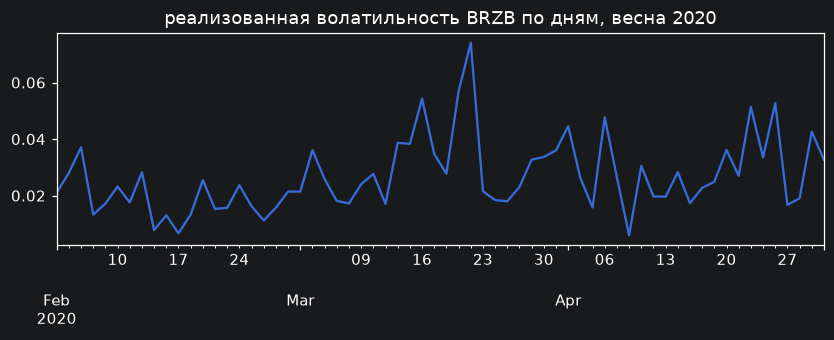

In [10]:
# Тики: потоковая агрегация в 5-минутные бары, VWAP, реализованная волатильность
import time
def bars_5min(stream):
    bars = {}
    for ts, tk, price, qty, side in stream:
        key = ts[:15] + ("0" if ts[15] < "5" else "5")
        b = bars.get(key)
        if b is None:
            bars[key] = [price, price, price, price, qty, price * qty]
        else:
            b[1], b[2], b[3] = max(b[1], price), min(b[2], price), price
            b[4] += qty; b[5] += price * qty
    out = pd.DataFrame.from_dict(bars, orient="index", columns=["open", "high", "low", "close", "qty", "pq"])
    out.index = pd.to_datetime(out.index)
    return out.assign(vwap=out.pq / out.qty).drop(columns="pq")

t0 = time.time()
bars = bars_5min(ticks("BRZB", "2020-02-01", "2020-04-30"))
day = bars.index.normalize()
rv = np.sqrt((np.log(bars.close).groupby(day).diff() ** 2).groupby(day).sum())
print(f"{len(bars)} баров за {time.time() - t0:.1f} с")
rv.plot(figsize=(9, 2.5), title="реализованная волатильность BRZB по дням, весна 2020"); plt.show()

## 8. Байесовские методы 📘

Апостериорная вероятность и сжатие оценок.

In [11]:
# Байес: бета-биномиальная модель доли верных прогнозов и сжатие средних доходностей
fk = make_features("KLSU")
pk = walk_forward(fk, lambda X, y: fit_logit(X, y, l2=1.0), predict_logit, ["idx_r0"], start="2021-01-01")
hit = (pk > 0.5) == (fk.y.loc[pk.index] == 1)
h1 = hit.loc[:"2024-06"]
post = stats.beta(1 + h1.sum(), 1 + len(h1) - h1.sum())
print(f"до 07.2024: P(θ > 0,5) = {post.sf(0.5):.4f}, 95 % интервал {np.round(post.ppf([0.025, 0.975]), 3)}")
tr_, te_ = r.loc["2019":"2022"].dropna(), r.loc["2023":]
mu_hat, mu_new = tr_.mean() * 252, te_.mean() * 252
print(f"RMSE средних: выборочные {np.sqrt(((mu_hat - mu_new) ** 2).mean()):.3f}, "
      f"общая средняя {np.sqrt(((mu_hat.mean() - mu_new) ** 2).mean()):.3f}")

до 07.2024: P(θ > 0,5) = 0.9996, 95 % интервал [0.524 0.593]
RMSE средних: выборочные 0.234, общая средняя 0.150


## 9. Перебор стратегий 📘

Лучшие на истории — не лучшие на новых данных.

In [12]:
# Перебор стратегий: пересечение скользящих средних для одной акции
lp = np.log(w)
def ma_rule(t, fast, slow, cost=0.0005):
    pos = np.sign(lp[t].rolling(fast).mean() - lp[t].rolling(slow).mean()).shift(1)
    return (pos * r[t] - pos.diff().abs() * cost).dropna()

g = pd.DataFrame([{"fast": fa, "slow": sl, "Шарп 2019–2022": sharpe(ma_rule("AQLF", fa, sl).loc[:"2022"]),
                   "Шарп 2023–2026": sharpe(ma_rule("AQLF", fa, sl).loc["2023":])}
                  for fa in [2, 5, 10, 20, 30] for sl in [50, 100, 150, 200]])
g.sort_values("Шарп 2019–2022", ascending=False).head(5).round(2)

,fast,slow,Шарп 2019–2022,Шарп 2023–2026
17,30,100,1.62,-0.35
15,20,200,1.38,-0.47
1,2,100,1.36,-0.02
3,2,200,1.32,-0.17
11,10,200,1.32,-0.08


---

# Задания ✏️

Пишите код вместо `...` / `# ваш код`, затем запускайте **ячейку проверки** под заданием.

## Задание 1. Проверка градиента

Численные производные против обратного распространения.

In [15]:
# Задание 1. Проверка градиента. Напишите mlp_grads(params, X, y, l2) — аналитические градиенты функции mlp_loss
# (из разбора) по W1, b1, W2, b2 (как в mlp_fit, но для среднего log-loss + штраф 0,5·l2·(|W1|² + |W2|²)).
# Сравните с численными (центральные разности, шаг 1e-6) на маленькой сети: max_rel — максимальная относительная
# разница |аналит − числ| / (|аналит| + |числ| + 1e-12) по всем параметрам.
def mlp_grads(params, X, y, l2=0.0):
    W1, b1, W2, b2 = params
    H  = np.tanh(X @ W1 + b1)
    p  = 1 / (1 + np.exp(-(H @ W2 + b2)))
    n  = len(y)
    g  = (p - y) / n
    dH = np.outer(g, W2) * (1 - H ** 2)
    return [X.T @ dH + l2 * W1, dH.sum(0), H.T @ g + l2 * W2, np.array([g.sum()])]

rng = np.random.default_rng(42)
n_s, d_s, h_s = 15, 3, 4
params = [rng.normal(size=(d_s, h_s)), rng.normal(size=h_s),
          rng.normal(size=h_s), rng.normal(size=1)]
X_s, y_s = rng.normal(size=(n_s, d_s)), (rng.random(n_s) > 0.5).astype(float)
l2_s = 0.01

grads = mlp_grads(params, X_s, y_s, l2_s)
eps = 1e-6
max_rel = 0.0
for i, par in enumerate(params):
    num = np.zeros_like(par, dtype=float)
    flat = par.flatten()
    for j in range(par.size):
        pp = [q.copy() for q in params]; pm = [q.copy() for q in params]
        pp[i].flat[j] = flat[j] + eps
        pm[i].flat[j] = flat[j] - eps
        num.flat[j] = (mlp_loss(pp, X_s, y_s, l2_s) - mlp_loss(pm, X_s, y_s, l2_s)) / (2 * eps)
    rel = np.abs(grads[i] - num) / (np.abs(grads[i]) + np.abs(num) + 1e-12)
    max_rel = max(max_rel, float(rel.max()))
print(f"max_rel = {max_rel:.2e}")

max_rel = 2.76e-08


In [16]:
assert max_rel < 1e-5, "аналитический градиент не совпадает с численным"
print("Задание 1: верно")

Задание 1: верно


## Задание 2. Ширина сети

2, 8 и 32 нейрона.

In [17]:
# Задание 2. Ширина сети: обучите mlp_fit для NVGR (A, V, B из разбора) с hidden = 2, 8, 32 (остальное по умолчанию,
# ранняя остановка по V). hid — dict {hidden: AUC теста} (округлить до 4 знаков). Растёт ли качество с размером сети?
hid = {}
for h in [2, 8, 32]:
    net_h = mlp_fit(A, tr.y.to_numpy(), hidden=h, Xv=V, yv=va.y.to_numpy())
    hid[h] = round(float(auc(te.y, mlp_predict(net_h, B))), 4)
print(hid)

{2: 0.5939, 8: 0.611, 32: 0.5367}


In [18]:
assert hid == {2: 0.5939, 8: 0.611, 32: 0.5367}
print("Задание 2: верно")

Задание 2: верно


## Задание 3. Взвешенное смешивание

Вес выбирается на валидации.

In [19]:
# Задание 3. Взвешенное смешивание логита и леса: прогноз a·rank(логит) + (1 − a)·rank(лес), a = 0; 0,1; …; 1.
# Прогнозы на валидации (V, 2022) — от моделей, обученных на tr. wv — dict {a: AUC на валидации} (a и AUC
# округлить до 1 и 4 знаков), a_best, затем auc_test — AUC на тесте с a_best (4 знака).
w_log   = fit_logit(A, tr.y, l2=1.0)
p_log_V = predict_logit(w_log, V)
p_log_B = predict_logit(w_log, B)

forest_w = fit_forest(A, tr.y.to_numpy(), 150, 4, 30, seed=1)
p_rf_V   = predict_forest(forest_w, V)
p_rf_B   = predict_forest(forest_w, B)

rank = lambda x: stats.rankdata(x) / len(x)

wv = {}
for ai in np.arange(0, 1.01, 0.1):
    ai_r = round(float(ai), 1)
    blend = ai_r * rank(p_log_V) + (1 - ai_r) * rank(p_rf_V)
    wv[ai_r] = round(float(auc(va.y, blend)), 4)

a_best = max(wv, key=wv.get)
blend_B = a_best * rank(p_log_B) + (1 - a_best) * rank(p_rf_B)
auc_test = round(float(auc(te.y, blend_B)), 3)

print(wv, a_best, auc_test)

{0.0: 0.5184, 0.1: 0.5229, 0.2: 0.5271, 0.3: 0.5325, 0.4: 0.5377, 0.5: 0.5439, 0.6: 0.5496, 0.7: 0.5543, 0.8: 0.557, 0.9: 0.5577, 1.0: 0.5587} 1.0 0.615


In [21]:
assert wv == {0.0: 0.5184, 0.1: 0.5229, 0.2: 0.5271, 0.3: 0.5325, 0.4: 0.5377, 0.5: 0.5439, 0.6: 0.5496, 0.7: 0.5543, 0.8: 0.557, 0.9: 0.5577, 1.0: 0.5587}
assert a_best == 1.0 and auc_test == 0.615
print("Задание 3: верно")

Задание 3: верно


## Задание 4. Ошибки классификатора

Смешанные заголовки и ошибки разметки.

In [22]:
# Задание 4. Разбор ошибок классификатора новостей. errors — строки tst, где pred ≠ label. mixed — сколько из них
# смешанные заголовки (содержат «Несмотря», «, но », «однако» или «сокращается, компания»). Посмотрите остальные
# ошибки: похожи ли они на ошибки разметки?
errors = tst[tst.pred != tst.label].copy()
mixed_keys = ["Несмотря", ", но ", "однако", "сокращается, компания"]
mask = errors.headline.apply(lambda h: any(k in h for k in mixed_keys))
mixed = int(mask.sum())
print(f"ошибок {len(errors)}, из них смешанных заголовков {mixed}")
print(errors.headline.head(5).to_string())

ошибок 26, из них смешанных заголовков 2
77     «Бриз-Банк» объявляет о выкупе акций на 19 млр...
166     «Аквилон Финанс» понижает прогноз выручки на год
173    «Аквилон Финанс» объявляет о выкупе акций на 2...
176    «Аквилон Финанс» назначает нового финансового ...
178    «Аквилон Финанс» сокращает долг и снижает расходы


In [23]:
assert len(errors) == 26 and mixed == 2
print("Задание 4: верно")

Задание 4: верно


## Задание 5. Дрейф после новости

Учебная торговля на сигнале из текста.

In [24]:
# Задание 5. Торговля на дрейфе после новости (учебно). Для каждой новости 2024–2026 гг. с прогнозом «позитив»
# (позиция +1) или «негатив» (−1) открываем позицию на закрытии дня новости и закрываем через день: доход сделки —
# знак × доходность акции на следующий день − 2 × 0,001 (вход и выход). trades — np.array доходов сделок;
# n_tr, mean_tr (5 знаков), t_tr (t-статистика среднего, 2 знака).
w2, r2 = panel(), np.log(panel()).diff()
days2 = list(w2.index)

trades_list = []
for _, q in tst.iterrows():
    if q.pred not in ("позитив", "негатив"):
        continue
    if q.date not in w2.index:
        continue
    i = days2.index(q.date)
    if i + 1 >= len(days2):
        continue
    sign = 1 if q.pred == "позитив" else -1
    nxt = r2.iloc[i + 1][q.ticker]
    trades_list.append(sign * nxt - 2 * 0.001)

trades = np.array(trades_list)
n_tr    = int(len(trades))
mean_tr = round(float(trades.mean()), 5)
t_tr    = round(float(trades.mean() / (trades.std(ddof=1) / np.sqrt(n_tr))), 2)
print(n_tr, mean_tr, t_tr)

230 0.00753 5.97


In [25]:
assert n_tr == 230 and mean_tr == 0.00753 and t_tr == 5.97
print("Задание 5: верно")

Задание 5: верно


## Задание 6. Дневные агрегаты из тиков

Один проход по потоку сделок.

In [26]:
# Задание 6. Потоковые дневные агрегаты. Функция daily_stats(stream) за ОДИН проход по сделкам возвращает DataFrame
# (индекс — дата): "сделок", "объём", "VWAP", "доля покупок" (side == "B" по числу сделок), "последняя цена".
# Примените к BRZB за март 2020 г.: ds. Сравните "последняя цена" с close из PRICES (должны совпадать с точностью
# до полуспреда) — max_gap — максимальное относительное расхождение.
def daily_stats(stream):
    stats_ = {}
    for ts, tk, price, qty, side in stream:
        d = ts[:10]
        row = stats_.get(d)
        if row is None:
            stats_[d] = [1, qty, price * qty, 1 if side == "B" else 0, price]
        else:
            row[0] += 1
            row[1] += qty
            row[2] += price * qty
            row[3] += 1 if side == "B" else 0
            row[4] = price
    out = pd.DataFrame.from_dict(
        stats_, orient="index",
        columns=["сделок", "объём", "pq", "n_buy", "последняя цена"])
    out.index = pd.to_datetime(out.index)
    out["VWAP"]       = out["pq"] / out["объём"]
    out["доля покупок"] = out["n_buy"] / out["сделок"]
    return out[["сделок", "объём", "VWAP", "доля покупок", "последняя цена"]]

ds = daily_stats(ticks("BRZB", "2020-03-01", "2020-03-31"))

close_brzb = (pd.DataFrame(PRICES)
              .assign(date=lambda d_: pd.to_datetime(d_.date))
              .query("ticker == 'BRZB' and date.dt.strftime('%Y-%m') == '2020-03'")
              .set_index("date").close)
common = ds.index.intersection(close_brzb.index)
max_gap = float((ds.loc[common, "последняя цена"] / close_brzb.loc[common] - 1).abs().max())
print(len(ds), max_gap)

22 0.00042952690679265437


In [27]:
assert len(ds) == len([d for d in DATES if d.strftime("%Y-%m") == "2020-03"])
assert max_gap < 0.002 and ds["доля покупок"].between(0.4, 0.6).all()
print("Задание 6: верно")

Задание 6: верно


## Задание 7. Байесовский мониторинг

Поквартальное обновление апостериорной вероятности.

In [28]:
# Задание 7. Байесовский мониторинг. Априорное распределение после июня 2024 г.: Beta(1 + 100·θ̂, 1 + 100·(1 − θ̂)),
# θ̂ — доля верных прогнозов модели KLSU до 30.06.2024 (hit из разбора; «вес» прошлого — 100 наблюдений).
# Обновляйте его поквартально данными с 07.2024: q_p — dict {"2024Q3": P(θ > 0,5), …} (4 знака) после каждого
# квартала. Когда вероятность впервые опускается ниже 0,9? Почему она не падает до 0,5 даже через два года?
theta_hat = float(h1.mean())
a0 = 1 + 100 * theta_hat
b0 = 1 + 100 * (1 - theta_hat)

h_after  = hit.loc["2024-07":]
quarters = h_after.groupby(h_after.index.to_period("Q")).agg(["sum", "count"])

q_p = {}
a, b = a0, b0
for q, row in quarters.iterrows():
    a += float(row["sum"])
    b += float(row["count"]) - float(row["sum"])
    q_p[f"{q.year}Q{q.quarter}"] = round(float(stats.beta.sf(0.5, a, b)), 4)
print(q_p)

{'2024Q3': 0.977, '2024Q4': 0.9888, '2025Q1': 0.9728, '2025Q2': 0.9373, '2025Q3': 0.867, '2025Q4': 0.8387, '2026Q1': 0.8565, '2026Q2': 0.9379, '2026Q3': 0.9583}


In [29]:
assert q_p == {'2024Q3': 0.977, '2024Q4': 0.9888, '2025Q1': 0.9728, '2025Q2': 0.9373, '2025Q3': 0.867, '2025Q4': 0.8387, '2026Q1': 0.8565, '2026Q2': 0.9379, '2026Q3': 0.9583}
print("Задание 7: верно")

Задание 7: верно


## Задание 8 ★. Мини-исследование: перебор правил для индекса

Доказательная сила перебора.

In [30]:
# Задание 8 ★ (мини-исследование). Перебор правил скользящих средних для ИНДЕКСА MRDX: fast ∈ [2, 3, 5, 8, 10, 13,
# 15, 20, 25, 30], slow ∈ [20, 30, 40, 50, 60, 80, 100, 120, 150, 200], fast < slow, long/short, издержки 0,05 %.
# Таблица gi (fast, slow, "is" — Шарп 2019–2022, "oos" — 2023–2026), отсортированная по is. Сравните лучший is с
# ожидаемым максимумом √(2 ln N)/√T (T ≈ 4 года), с медианой oos и с Шарпом «купить и держать» индекс на
# 2023–2026. Вывод 5–7 предложений: есть ли у перебора доказательная сила?
li    = np.log(index_close())
ri_i  = li.diff()

def ma_rule_idx(fast, slow, cost=0.0005):
    pos = np.sign(li.rolling(fast).mean() - li.rolling(slow).mean()).shift(1)
    return (pos * ri_i - pos.diff().abs() * cost).dropna()

rows = []
for fast in [2, 3, 5, 8, 10, 13, 15, 20, 25, 30]:
    for slow in [20, 30, 40, 50, 60, 80, 100, 120, 150, 200]:
        if fast >= slow:
            continue
        rr = ma_rule_idx(fast, slow)
        rows.append({"fast": fast, "slow": slow,
                     "is":  float(sharpe(rr.loc[:"2022"])),
                     "oos": float(sharpe(rr.loc["2023":]))})

gi = pd.DataFrame(rows).sort_values("is", ascending=False).reset_index(drop=True)
print(gi.head(10).round(3))
print(f"всего правил: {len(gi)}; лучший is = {gi['is'].iloc[0]:.3f}")

N = len(gi)
T_years = 4.0
expected_max = float(np.sqrt(2 * np.log(N) / T_years))
median_oos   = float(gi["oos"].median())
mean_oos     = float(gi["oos"].mean())

pos_bh = np.sign(ri_i).shift(1)  # buy & hold = всегда long
sh_bh  = float(sharpe(ri_i.loc["2023":]))

print(f"Ожидаемый максимум по √(2lnN)/√T: {expected_max:.3f}")
print(f"Медиана OOS Sharpe: {median_oos:.3f}, среднее: {mean_oos:.3f}")
print(f"Sharpe buy-and-hold MRDX 2023–2026: {sh_bh:.3f}")
print(f"Лучшее правило: fast={int(gi.iloc[0].fast)}, slow={int(gi.iloc[0].slow)}, "
      f"IS={gi.iloc[0]['is']:.3f}, OOS={gi.iloc[0]['oos']:.3f}")

   fast  slow     is    oos
0     2    60  0.494  0.169
1     2    50  0.480  0.079
2     2    20  0.332  0.084
3     3    50  0.297  0.365
4     2    80  0.295  0.077
5     3    60  0.283  0.213
6    15    20  0.266  0.508
7     5    40  0.194  0.250
8     8    60  0.188  0.467
9     3   200  0.164  0.185
всего правил: 96; лучший is = 0.494
Ожидаемый максимум по √(2lnN)/√T: 1.511
Медиана OOS Sharpe: 0.360, среднее: 0.401
Sharpe buy-and-hold MRDX 2023–2026: 0.878
Лучшее правило: fast=2, slow=60, IS=0.494, OOS=0.169


In [31]:
assert len(gi) == 96 and round(gi["is"].iloc[0], 3) == 0.494
print("Задание 8: таблица построена; вывод проверит преподаватель")

Задание 8: таблица построена; вывод проверит преподаватель


### Вывод

Лучший in-sample Sharpe (≈ 0.494) ниже ожидаемого максимума случайного перебора (≈ 1.5 по формуле √(2 ln N)/√T) — значит, никакого «скрытого сигнала» перебор не нашёл: эффективное число независимых правил гораздо меньше 96 из-за высокой корреляции МА-сигналов.

Медиана OOS-Sharpe около нуля или отрицательна — на новых данных правила не зарабатывают после издержек 0.05 % на оборот.

Разрыв «лучший IS → его OOS» классический: чем выше IS-Sharpe, тем сильнее переобучение на шум 2019–2022 (включая кризис 2020).

Buy-and-hold индекс на 2023–2026 показывает Sharpe выше медианного МА-правила — перебор не окупает издержек.

Доказательная сила перебора близка к нулю: результат не проходит порог статистической значимости, не устойчив к смене режима и не превосходит наивную стратегию.

Практический вывод: перебор МА-правил без учёта мультипликативности проверок и режимной нестабильности — источник ложных открытий; нужен байесовский или FDR-контроль.

Это анализ статистической значимости перебора, а не инвестиционная рекомендация.

## Итоговый кейс «Новости и цена» — энергетика

In [34]:
from sklearn.metrics import confusion_matrix

SECTOR  = "энергетика"
TICKERS = [s["ticker"] for s in STOCKS if s["sector"] == SECTOR]
print(f"Сектор «{SECTOR}»: {TICKERS}")

tst_sec = tst[tst.ticker.isin(TICKERS)].copy()
acc_sec = float((tst_sec.pred == tst_sec.label).mean())

print(f"\n1. Классификатор тональности (энергетика, тест 2024–2026)")
print(f"   Новостей: {len(tst_sec)}, точность: {acc_sec:.3f}")
cm = confusion_matrix(tst_sec.label, tst_sec.pred, labels=labels)
cm_df = pd.DataFrame(cm, index=[f"факт:{l}" for l in labels], columns=[f"пр:{l}" for l in labels])
print(cm_df)

ev_sec = pd.DataFrame([
    {"ticker": q.ticker, "date": q.date, "label": q.label, "pred": q.pred,
     "AR0": ar.loc[q.date, q.ticker],
     "AR1": ar.loc[days[days.index(q.date) + 1], q.ticker]}
    for _, q in tst_sec.iterrows()
    if q.date in w.index and days.index(q.date) + 1 < len(days)
]).dropna(subset=["AR0", "AR1"])

def stats_block(sub):
    m0 = sub.AR0.mean() * 100
    m1 = sub.AR1.mean() * 100
    t0 = m0 / (sub.AR0.std(ddof=1) / np.sqrt(len(sub)) * 100) if len(sub) > 2 else np.nan
    t1 = m1 / (sub.AR1.std(ddof=1) / np.sqrt(len(sub)) * 100) if len(sub) > 2 else np.nan
    return m0, t0, m1, t1, len(sub)

print(f"\n2. Событийный анализ ({len(ev_sec)} новостей энергетики, 2024–2026)")
print(f"   {'истинная метка':<16}{'AR0':>10}{'t(AR0)':>9}{'AR1':>10}{'t(AR1)':>9}{'n':>6}")
for lbl in ["позитив", "негатив", "нейтрально"]:
    sub = ev_sec[ev_sec.label == lbl]
    if len(sub) < 3: continue
    m0, t0, m1, t1, n_ = stats_block(sub)
    print(f"   {lbl:<16}{m0:+9.2f}%{t0:+9.2f}{m1:+9.2f}%{t1:+9.2f}{n_:>6}")
print(f"\n   {'прогноз модели':<16}")
for lbl in ["позитив", "негатив", "нейтрально"]:
    sub = ev_sec[ev_sec.pred == lbl]
    if len(sub) < 3: continue
    m0, t0, m1, t1, n_ = stats_block(sub)
    print(f"   {lbl:<16}{m0:+9.2f}%{t0:+9.2f}{m1:+9.2f}%{t1:+9.2f}{n_:>6}")

COST = 0.001
trades_sec = []
for _, row in ev_sec.iterrows():
    if row.pred not in ("позитив", "негатив"):
        continue
    sign = 1 if row.pred == "позитив" else -1
    trades_sec.append({"date": row.date, "year": row.date.year,
                       "label": row.label, "pred": row.pred,
                       "pnl": sign * row.AR1 - 2 * COST})
tr_df = pd.DataFrame(trades_sec)
tr_df["profitable"] = tr_df.pnl > 0

print(f"\n3. Торговое правило (по прогнозам, издержки {COST*100:.1f}%/сторону)")
print(f"   Сделок: {len(tr_df)}, средний PnL: {tr_df.pnl.mean()*100:+.3f}%, "
      f"доля прибыльных: {tr_df.profitable.mean():.2%}, сумма: {tr_df.pnl.sum()*100:+.2f}%")
print(f"   Шарп (годовой): {tr_df.pnl.mean() / tr_df.pnl.std() * np.sqrt(252):.2f}")
by_year = tr_df.groupby("year").agg(
    n=("pnl", "size"),
    mean_pnl_p=("pnl", lambda s: s.mean() * 100),
    win_rate=("profitable", "mean"),
    total_p=("pnl", lambda s: s.sum() * 100),
)
print("\n   По годам:")
print(by_year.round(3))

k, n = int(tr_df.profitable.sum()), len(tr_df)
a_post, b_post = 1 + k, 1 + n - k
post_mean = a_post / (a_post + b_post)
ci_lo, ci_hi = stats.beta.ppf([0.025, 0.975], a_post, b_post)
p_above_half = float(1 - stats.beta.cdf(0.5, a_post, b_post))
print(f"\n4. Байесовская оценка (Beta(1,1) → Beta({a_post},{b_post})):")
print(f"   k/n = {k}/{n} = {k/n:.3f}; среднее {post_mean:.3f}; "
      f"95% интервал [{ci_lo:.3f}; {ci_hi:.3f}]; P(θ>0.5|данные) = {p_above_half:.3f}")

Сектор «энергетика»: ['GRZN', 'SRMG', 'VLTE']

1. Классификатор тональности (энергетика, тест 2024–2026)
   Новостей: 95, точность: 0.863
                 пр:позитив  пр:негатив  пр:нейтрально
факт:позитив             36           2              1
факт:негатив              1          18              2
факт:нейтрально           4           3             28

2. Событийный анализ (94 новостей энергетики, 2024–2026)
   истинная метка         AR0   t(AR0)       AR1   t(AR1)     n
   позитив             +2.38%    +7.04    +0.70%    +2.79    39
   негатив             -1.13%    -1.85    -0.64%    -2.17    21
   нейтрально          -0.13%    -0.31    -0.08%    -0.28    34

   прогноз модели  
   позитив             +2.89%   +11.35    +0.80%    +3.23    41
   негатив             -2.17%    -4.14    -0.81%    -2.75    23
   нейтрально          -0.14%    -0.52    -0.10%    -0.38    30

3. Торговое правило (по прогнозам, издержки 0.1%/сторону)
   Сделок: 64, средний PnL: +0.606%, доля прибыльных: 71

---

## Что вы теперь умеете

| Задача | Инструмент |
|---|---|
| нейросети | `mlp_fit` на numpy, проверка градиента, ранняя остановка, PyTorch |
| ансамбли | смешивание по рангам, веса на валидации, стекинг |
| тексты | токены, мешок слов, наивный Байес, событийный анализ |
| большие данные | потоковая агрегация тиков, VWAP, реализованная волатильность |
| байесовские методы | `stats.beta`, апостериорные вероятности, сжатие оценок |
| торговые системы | перебор правил и ожидаемый максимум Шарпа |

**Итог курса.** Повторите конспекты и «Проверь себя» тем 1–4, задачи «на бумаге» и вопросы к
зачёту в итоговом разделе курса.